# Seleção e diagnóstico da série (Níger)
**Variável:** inflação alimentar mensal, `inflacao_alimentar_log_pct` = 100·Δln(IPC alimentar).

**Escolha do país:** o Níger é um dos países com maior peso da agricultura no PIB (≈ 38 %) e menor rendimento da amostra, o que o torna particularmente exposto a choques sobre a produção alimentar. Distingue-se sobretudo pela sazonalidade: no treino, tem a maior amplitude sazonal dos 15 países (≈ 5,7, contra ≈ 1,1 em Portugal) e uma autocorrelação elevada no lag 12 (≈ 0,41). A série está completa e regular, adequada à modelização SARIMA.

In [47]:
#%pip install pandas matplotlib statsmodels

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import month_plot, plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings("ignore")


plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'

import os
os.makedirs('../resultados/graficos/05_sarima', exist_ok=True)   ### pasta para guardar as figuras

In [49]:

url = ('https://raw.githubusercontent.com/leandromicael123/Aquecimento-global/'
       'Primeira-parte/dados/processados/painel_longo.csv')
painel = pd.read_csv(url, parse_dates=['data'])

niger = painel[painel['pais_iso3'] == 'NER'].set_index('data').sort_index()
serie = niger['inflacao_alimentar_log_pct']

print('Frequência inferida:', pd.infer_freq(serie.index))
print('Datas duplicadas:', serie.index.duplicated().sum())
print('Valores em falta:', serie.isna().sum())
print('Início:', serie.index.min().date(), '| Fim:', serie.index.max().date(), '| n =', len(serie))

Frequência inferida: MS
Datas duplicadas: 0
Valores em falta: 0
Início: 2000-02-01 | Fim: 2025-12-01 | n = 311


A série é mensal e regular (frequência `MS`), sem datas duplicadas nem valores em falta: 311 observações, de fev/2000 a dez/2025. Começa em fevereiro porque a primeira diferença do log perde a observação inicial.

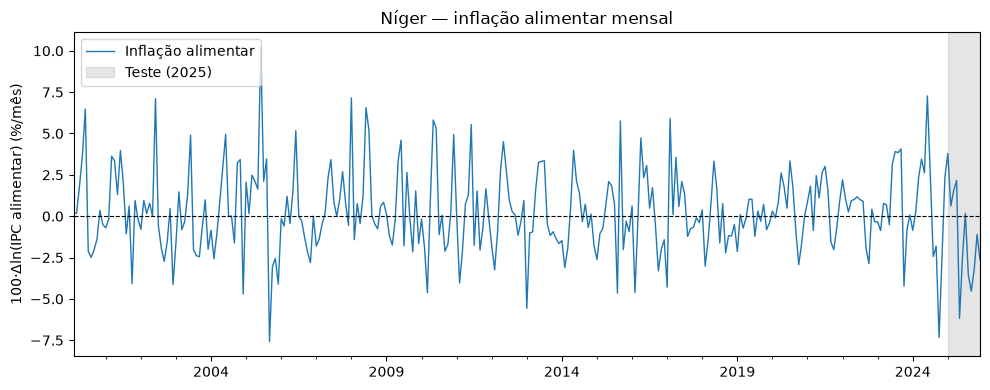

Média do treino: 0.3


In [50]:
fig, ax = plt.subplots(figsize=(10, 4))
serie.plot(ax=ax, linewidth=1, label='Inflação alimentar')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.axvspan('2025-01-01', '2025-12-01', color='grey', alpha=0.2,
           label='Teste (2025)')
ax.set_title('Níger — inflação alimentar mensal')
ax.set_xlabel('')
ax.set_ylabel('100·Δln(IPC alimentar) (%/mês)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('../resultados/graficos/05_sarima/01_serie.png', dpi=300)
plt.show()

print('Média do treino:', round(serie[:'2024-12-01'].mean(), 2))

Não se observa tendência: a série oscila em torno de um nível constante (média do treino ≈ 0,30 %/mês). Os valores extremos concentram-se em 2005 (máximo de +10,2 em junho e mínimo de −7,6 em setembro) e em 2024. A amplitude das oscilações é menor entre 2019 e 2022 e volta a aumentar em 2024, o que sugere variância não constante; este ponto deve ser verificado nos resíduos e tem impacto nos intervalos de previsão (secções 4.2–4.3). O ano de 2025 (sombreado) é o período de teste e não é usado nas decisões.

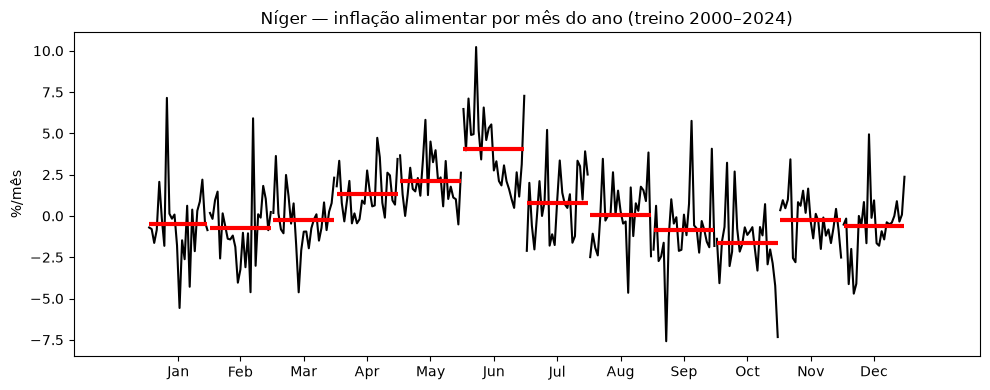

Média de outubro (treino): -1.64


In [51]:
treino = serie[niger['amostra_temporal'] == 'treino_ate_2024']

fig, ax = plt.subplots(figsize=(10, 4))
month_plot(treino, ax=ax)
ax.set_title('Níger — inflação alimentar por mês do ano (treino 2000–2024)')
ax.set_ylabel('%/mês')
plt.tight_layout()
plt.savefig('../resultados/graficos/05_sarima/02_grafico_sazonal.png', dpi=300)  ### guardar para o relatório
plt.show()

print('Média de outubro (treino):', round(treino[treino.index.month == 10].mean(), 2))

O gráfico sazonal por mês (`month_plot`), nos dados de treino, mostra sazonalidade anual: a inflação sobe de março a junho (máximo em junho, ≈ 4 %/mês) e desce de julho a outubro (mínimo em outubro, ≈ −1,6 %/mês). Com dados mensais, o período sazonal é s = 12.

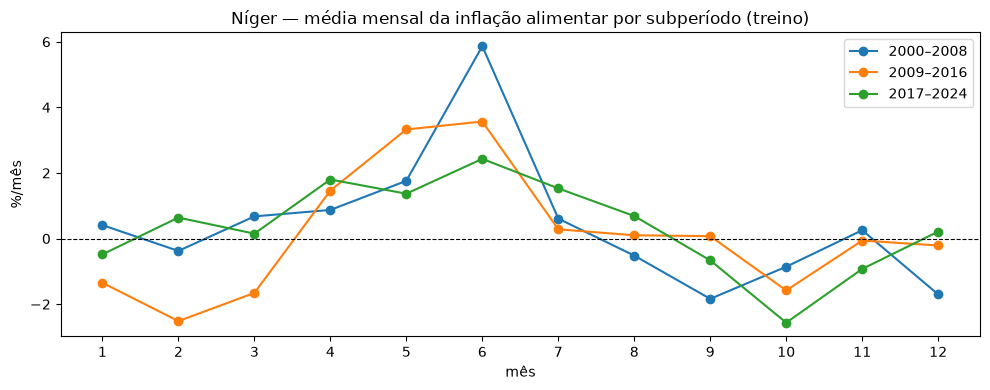

Amplitude sazonal:
2000–2008    7.70
2009–2016    6.08
2017–2024    4.99
dtype: float64
Mês do máximo: {'2000–2008': 6, '2009–2016': 6, '2017–2024': 6}
Mês do mínimo: {'2000–2008': 9, '2009–2016': 2, '2017–2024': 10}


In [52]:
periodos = {'2000–2008': ('2000', '2008'),
            '2009–2016': ('2009', '2016'),
            '2017–2024': ('2017', '2024')}

medias_mensais = pd.DataFrame({nome: treino[ini:fim].groupby(treino[ini:fim].index.month).mean()
                               for nome, (ini, fim) in periodos.items()})
medias_mensais.index.name = 'mês'

fig, ax = plt.subplots(figsize=(10, 4))
medias_mensais.plot(ax=ax, marker='o')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')            ### referência: inflação zero
ax.set_xticks(range(1, 13))
ax.set_title('Níger — média mensal da inflação alimentar por subperíodo (treino)')
ax.set_ylabel('%/mês')
plt.tight_layout()
plt.savefig('../resultados/graficos/05_sarima/03_sazonalidade_por_periodo.png', dpi=300)
plt.show()

print('Amplitude sazonal:')
print((medias_mensais.max() - medias_mensais.min()).round(2))
print('Mês do máximo:', medias_mensais.idxmax().to_dict())
print('Mês do mínimo:', medias_mensais.idxmin().to_dict())

**Alterações de comportamento.** O padrão sazonal não se mantém constante ao longo do tempo. O máximo ocorre sempre em junho, mas a amplitude sazonal diminui de período para período (≈ 7,7 em 2000–2008, ≈ 6,1 em 2009–2016 e ≈ 5,0 em 2017–2024) e o mínimo desloca-se (setembro, fevereiro e outubro, respetivamente). Uma sazonalidade que se altera ao longo do tempo é estocástica, o que reforça a utilização de uma diferença sazonal (D = 1).

In [53]:
treino = serie[niger['amostra_temporal'] == 'treino_ate_2024']
teste  = serie[niger['amostra_temporal'] == 'teste_2025']

print('Treino:', treino.index.min().date(), '→', treino.index.max().date(), '| n =', len(treino))
print('Teste: ', teste.index.min().date(),  '→', teste.index.max().date(),  '| n =', len(teste))

Treino: 2000-02-01 → 2024-12-01 | n = 299
Teste:  2025-01-01 → 2025-12-01 | n = 12


Os últimos 12 meses (jan–dez 2025) ficam reservados para teste e não são usados na seleção dos modelos. O treino tem 299 observações (fev/2000–dez/2024). Todas as decisões seguintes usam apenas o treino.

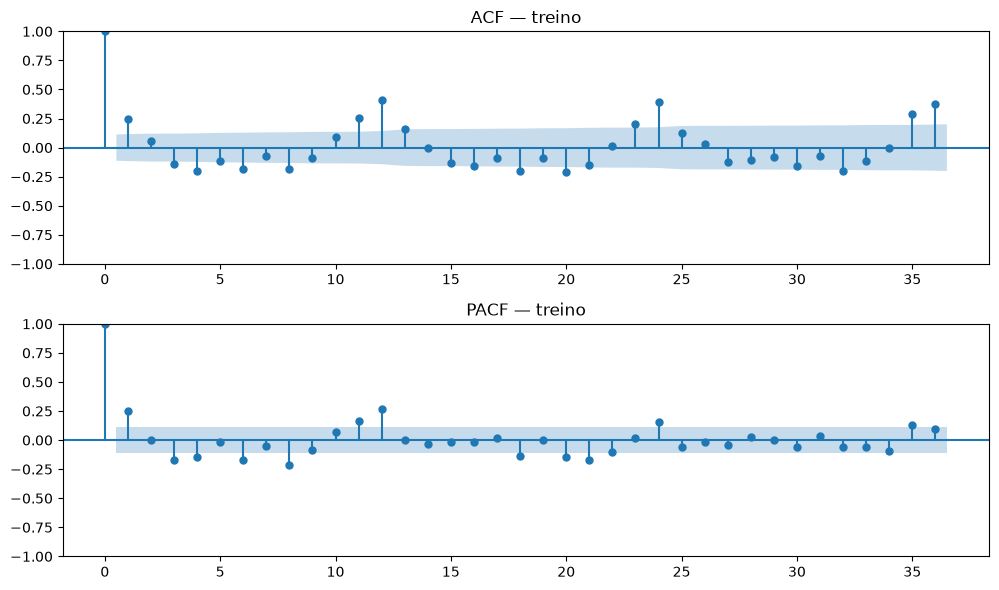

In [54]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
plot_acf(treino, lags=36, ax=ax[0])
ax[0].set_title('ACF — treino')
plot_pacf(treino, lags=36, ax=ax[1], method='ywm')
ax[1].set_title('PACF — treino')
plt.tight_layout()
plt.savefig('../resultados/graficos/05_sarima/04_acf_pacf_treino.png', dpi=300)
plt.show()

In [55]:
adf1 = adfuller(treino, autolag='AIC', regression='c')
adf1_result = pd.Series(adf1[0:4], index=['ADF Test Statistic', 'P-Value',
                                          '# Lags Used', '# Observations Used'])
print(adf1_result)

kpss1 = kpss(treino, regression='c', nlags='auto')
kpss1_result = pd.Series(kpss1[0:3], index=['KPSS Test Statistic', 'P-Value', '# Lags Used'])
print(kpss1_result)

ADF Test Statistic      -3.835238
P-Value                  0.002567
# Lags Used             11.000000
# Observations Used    287.000000
dtype: float64
KPSS Test Statistic    0.031946
P-Value                0.100000
# Lags Used            1.000000
dtype: float64


Nos primeiros lags, a ACF decai rapidamente. O ADF rejeita a raiz unitária (p < 0,05) e o KPSS não rejeita a estacionaridade (p ≥ 0,10), pelo que não é necessária diferenciação simples (d = 0). A série já está em logaritmo e diferenciada, por isso não se aplica outra transformação.

Contudo, a ACF decai muito lentamente nos lags sazonais (≈ 0,41, 0,39 e 0,38 nos lags 12, 24 e 36), sinal de não estacionaridade sazonal. Estes testes avaliam a raiz unitária simples, não a sazonal.

ADF Test Statistic    -6.330243e+00
P-Value                1.828602e-09
# Lags Used            1.100000e+01
# Observations Used    2.750000e+02
dtype: float64
KPSS Test Statistic    0.022495
P-Value                0.100000
# Lags Used            1.000000
dtype: float64


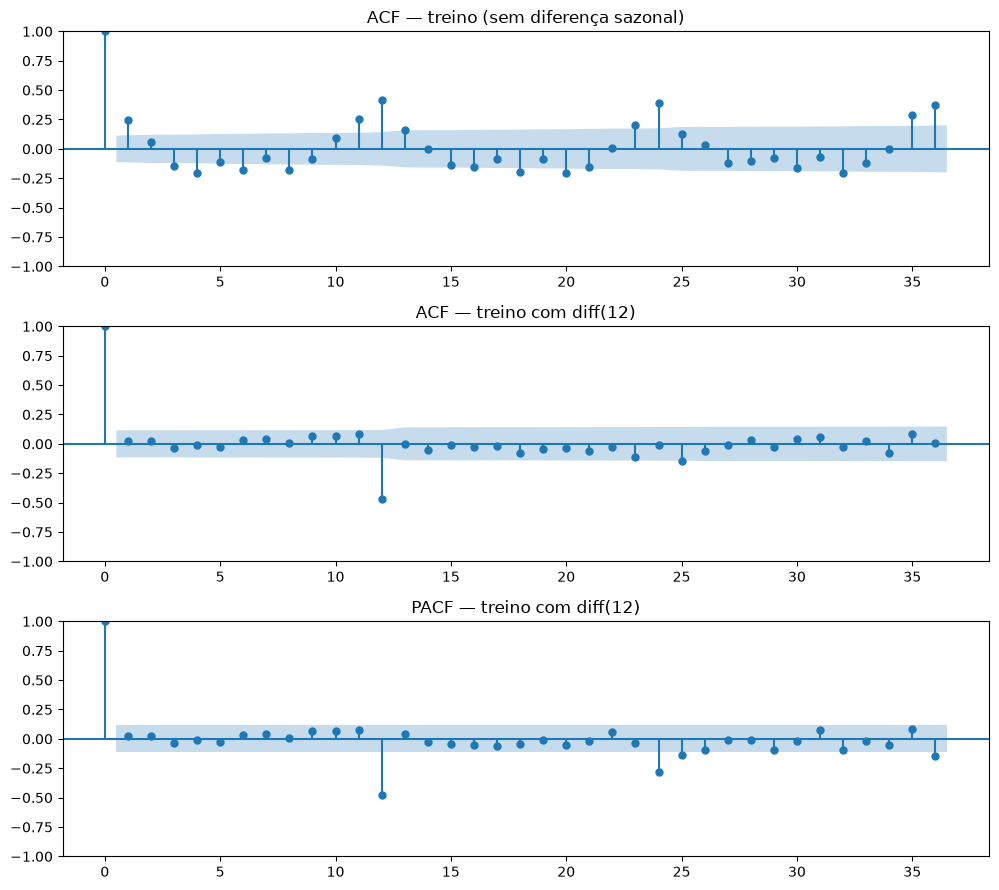

In [56]:
treino_d12 = treino.diff(12).dropna()

adf2 = adfuller(treino_d12, autolag='AIC', regression='n')
adf2_result = pd.Series(adf2[0:4], index=['ADF Test Statistic', 'P-Value',
                                          '# Lags Used', '# Observations Used'])
print(adf2_result)

kpss2 = kpss(treino_d12, regression='c', nlags='auto')
kpss2_result = pd.Series(kpss2[0:3], index=['KPSS Test Statistic', 'P-Value', '# Lags Used'])
print(kpss2_result)

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
plot_acf(treino, lags=36, ax=ax[0])
ax[0].set_title('ACF — treino (sem diferença sazonal)')
plot_acf(treino_d12, lags=36, ax=ax[1])
ax[1].set_title('ACF — treino com diff(12)')
plot_pacf(treino_d12, lags=36, ax=ax[2], method='ywm')
ax[2].set_title('PACF — treino com diff(12)')
plt.tight_layout()
plt.savefig('../resultados/graficos/05_sarima/05_acf_pacf_diff12.png', dpi=300)
plt.show()

Após a diferença sazonal, as autocorrelações nos lags 24 e 36 deixam de ser significativas. O ADF rejeita a raiz unitária (p < 0,001) e o KPSS não rejeita a estacionaridade (p ≥ 0,10), pelo que as duas evidências apontam no mesmo sentido. Juntamente com a alteração do padrão sazonal ao longo do tempo, adota-se **D = 1, d = 0 e s = 12**.

Na série diferenciada, a ACF tem um pico negativo isolado no lag 12 (≈ −0,47) e corta a seguir, enquanto a PACF decai nos lags 12, 24 e 36. Este padrão sugere uma componente MA sazonal de ordem 1 (Q = 1). As autocorrelações nos primeiros lags são próximas de zero, o que torna plausível p = q = 0. Candidato inicial para a secção 4.2: SARIMA(0,0,0)(0,1,1)₁₂; a comparação com uma especificação sem diferença sazonal (D = 0) fica para a secção 4.2.